# 06 · Anomaly Detection and Root-Cause Notes

Three detectors, each at a different level, and each flag explained in plain words:

| Detector | Level | Question | Method |
|---|---|---|---|
| **A · Battery resistance** | voltage-sag event | Did the pack sag more than expected *for its temperature*? | expected resistance vs temperature (robust fit), robust z-score of the residual |
| **B · Unexpected consumption** | trip | Did a trip use more or less energy than its conditions explain? | leave-one-out ridge model of consumption, robust z-score of the residual |
| **C · Unusual trip profile** | trip | Is the overall combination of a trip's signals unusual for its season? | Isolation Forest on season-normalised features |
| **D · Signal-quality flags** | trip | Which recordings carry known sensor or logging problems? | flags set in notebook 02 |

A flag means **"worth an engineer's look"**, not "fault". Thresholds: robust |z| > 3.5 (the common modified-z rule),
and the 10 % most isolated trips for the Isolation Forest.

In [1]:
from pathlib import Path
import os
import warnings

os.environ.setdefault("LOKY_MAX_CPU_COUNT", str(os.cpu_count()))
warnings.filterwarnings("ignore", category=UserWarning)

import duckdb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.ensemble import IsolationForest
from sklearn.linear_model import HuberRegressor, Ridge
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DB_PATH = ROOT / "data" / "warehouse" / "volvo.duckdb"
REPORTS = ROOT / "reports"
FIGURES = REPORTS / "figures"
SEED = 42
Z_LIMIT = 3.5
SEASON_COLORS = {"summer": "#e6550d", "winter": "#3182bd"}

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 220)
pd.set_option("display.max_colwidth", 120)
con = duckdb.connect(str(DB_PATH))


def robust_z(x):
    x = np.asarray(x, dtype=float)
    med = np.nanmedian(x)
    mad = np.nanmedian(np.abs(x - med))
    return 0.6745 * (x - med) / mad


flags = []  # one row per flag: level, trip_id, time_s, detector, score, reason

## A · Battery resistance anomalies (event level)

Notebook 04 showed apparent pack resistance falling steeply as the battery warms. The expected resistance is fitted as
a smooth curve of battery temperature, log(R) ~ quadratic(T), with a Huber loss so outliers cannot bend the curve.
An event is flagged when its residual is extreme.

In [2]:
ev = con.sql("SELECT * FROM signal.sag_events WHERE apparent_resistance_mohm IS NOT NULL ORDER BY trip_id, start_s").df()
curve = make_pipeline(PolynomialFeatures(2), StandardScaler(), HuberRegressor(max_iter=1000))
curve.fit(ev[["batt_temp_c"]], np.log(ev.apparent_resistance_mohm))
ev["expected_resistance_mohm"] = np.exp(curve.predict(ev[["batt_temp_c"]]))
ev["resistance_ratio"] = ev.apparent_resistance_mohm / ev.expected_resistance_mohm
ev["z"] = robust_z(np.log(ev.resistance_ratio))
ev["flag"] = ev.z.abs() > Z_LIMIT
print(f"events: {len(ev)}, flagged: {ev.flag.sum()} ({ev.flag.mean():.1%})")
ev[ev.flag][["trip_id", "start_s", "batt_temp_c", "soc_pct", "current_at_max_sag_a", "max_sag_v",
             "apparent_resistance_mohm", "expected_resistance_mohm", "z"]].round(1)

events: 556, flagged: 18 (3.2%)


,trip_id,start_s,batt_temp_c,soc_pct,current_at_max_sag_a,max_sag_v,apparent_resistance_mohm,expected_resistance_mohm,z
40,TripA24,94.8,18.0,79.6,-144.9,17.5,137.4,97.4,4.2
41,TripA24,98.6,18.0,79.4,-154.9,18.6,135.6,97.4,4.1
112,TripB02,1346.0,16.0,68.0,-111.7,17.1,187.0,104.0,7.2
229,TripB09,2589.3,10.0,27.8,-110.4,16.4,180.5,132.7,3.8
230,TripB09,2599.6,10.0,27.2,-100.8,16.1,198.1,132.7,4.9
243,TripB10,755.1,5.0,72.2,-69.5,16.1,252.3,171.5,4.7
252,TripB10,1010.0,8.0,62.8,-148.2,26.7,203.5,146.2,4.1
285,TripB14,586.0,4.0,80.9,-104.7,21.2,247.2,181.6,3.8
308,TripB14,2510.9,13.0,49.4,-119.6,17.5,172.7,116.5,4.8
309,TripB14,2523.7,13.0,48.8,-97.0,15.5,196.9,116.5,6.4


In [3]:
def resistance_reason(r):
    parts = [f"resistance {r.apparent_resistance_mohm:.0f} mΩ vs about {r.expected_resistance_mohm:.0f} mΩ expected at "
             f"{r.batt_temp_c:.0f} °C ({r.resistance_ratio:.1f}×)"]
    if r.z > 0:
        if r.soc_pct == r.soc_pct and r.soc_pct < 50:
            parts.append(f"SoC {r.soc_pct:.0f} %: the expected curve ignores SoC, and resistance is higher in the lower half")
        if -r.current_at_max_sag_a < 120:
            parts.append(f"moderate current ({-r.current_at_max_sag_a:.0f} A), so the estimate is noisier")
        if r.batt_temp_c <= 2:
            parts.append("battery near freezing")
        neighbours = ev[(ev.trip_id == r.trip_id) & ev.flag]
        if len(neighbours) >= 3:
            parts.append(f"{len(neighbours)} flagged events in this trip: a persistent state, not a one-off spike")
    else:
        parts.append("lower than expected: the reference voltage may have been taken just after regeneration")
    return "; ".join(parts)


for r in ev[ev.flag].itertuples():
    flags.append(dict(level="event", trip_id=r.trip_id, time_s=r.start_s, detector="A · battery resistance",
                      score=round(r.z, 2), reason=resistance_reason(r)))
print(f"{len(flags)} event-level flags")

18 event-level flags


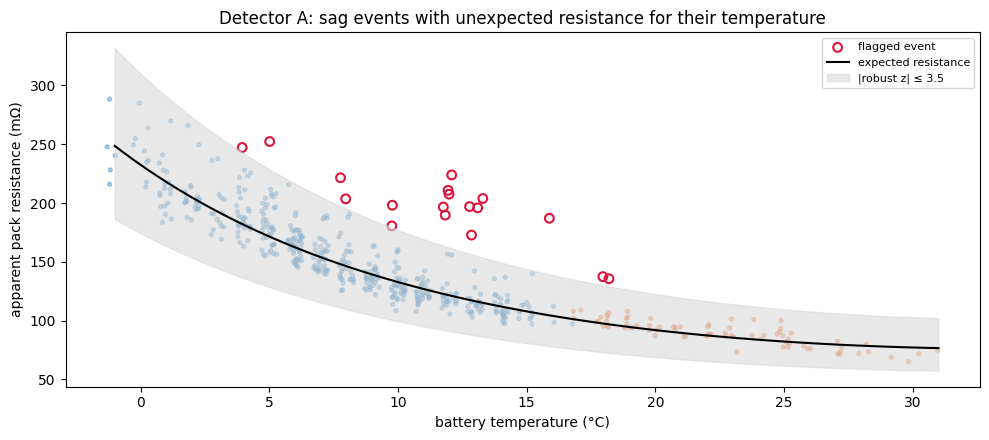

In [4]:
grid = pd.DataFrame({"batt_temp_c": np.linspace(ev.batt_temp_c.min(), ev.batt_temp_c.max(), 100)})
expected = np.exp(curve.predict(grid))
mad = np.median(np.abs(np.log(ev.resistance_ratio) - np.median(np.log(ev.resistance_ratio))))
band = np.exp(Z_LIMIT * mad / 0.6745)
fig, ax = plt.subplots(figsize=(10, 4.5))
jitter = np.random.default_rng(SEED).uniform(-0.3, 0.3, len(ev))
ok = ~ev.flag
ax.scatter(ev.batt_temp_c[ok] + jitter[ok], ev.apparent_resistance_mohm[ok], s=8, alpha=0.4,
           c=ev.season[ok].map(SEASON_COLORS))
ax.scatter(ev.batt_temp_c[ev.flag] + jitter[ev.flag], ev.apparent_resistance_mohm[ev.flag], s=40, facecolors="none",
           edgecolors="crimson", lw=1.5, label="flagged event")
ax.plot(grid.batt_temp_c, expected, "k-", lw=1.5, label="expected resistance")
ax.fill_between(grid.batt_temp_c, expected / band, expected * band, color="0.85", alpha=0.6, label=f"|robust z| ≤ {Z_LIMIT}")
ax.set(xlabel="battery temperature (°C)", ylabel="apparent pack resistance (mΩ)",
       title="Detector A: sag events with unexpected resistance for their temperature")
ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(FIGURES / "06_resistance_anomalies.png", dpi=150)
plt.show()

## B · Unexpected consumption (trip level)

Consumption per 100 km is modelled from what should explain it: ambient temperature, mean driving speed, share of
time stopped, heating power and A/C power. Each trip is predicted by a model trained on the **other 69 trips**
(leave-one-out), so no trip explains itself. A trip is flagged when its residual is extreme.

In [5]:
trip = con.sql("""
    WITH d AS (
        SELECT c.trip_id, avg(c.speed_kmh) AS mean_speed_kmh, avg(c.ambient_temp_c) AS ambient_c,
               coalesce(avg(c.heating_power_can_kw), 0) AS heating_kw, coalesce(avg(c.aircon_power_kw), 0) AS aircon_kw,
               avg(abs(c.accel_long_ms2)) AS mean_abs_accel
        FROM clean.trip_signals c JOIN signal.samples s USING (trip_id, row_idx)
        WHERE s.phase = 'driving' GROUP BY 1),
    st AS (SELECT trip_id, coalesce(sum(duration_s) FILTER (WHERE phase = 'stopped'), 0) / sum(duration_s) AS stopped_share
           FROM signal.segments GROUP BY 1),
    sg AS (SELECT trip_id, count(*) AS sag_events, median(apparent_resistance_mohm) AS resistance_mohm
           FROM signal.sag_events GROUP BY 1)
    SELECT t.trip_id, t.season, t.route, e.consumption_kwh_per_100km, e.regen_share_pct, e.heating_share_pct,
           e.distance_km_integrated AS distance_km, r.batt_temp_start_c, r.rise_rate_c_per_h,
           d.* EXCLUDE (trip_id), st.stopped_share, coalesce(sg.sag_events, 0) AS sag_events, sg.resistance_mohm
    FROM clean.trips t JOIN signal.trip_energy e USING (trip_id) JOIN signal.temp_rise r USING (trip_id)
    JOIN d USING (trip_id) JOIN st USING (trip_id) LEFT JOIN sg USING (trip_id)
    ORDER BY t.trip_id
""").df()

X_COLS = ["ambient_c", "mean_speed_kmh", "stopped_share", "heating_kw", "aircon_kw"]
pred = np.zeros(len(trip))
for i in range(len(trip)):
    train = trip.drop(index=i)
    m = make_pipeline(StandardScaler(), Ridge(alpha=1.0)).fit(train[X_COLS], train.consumption_kwh_per_100km)
    pred[i] = m.predict(trip.loc[[i], X_COLS])[0]
trip["expected_kwh_per_100km"] = pred
trip["consumption_residual"] = trip.consumption_kwh_per_100km - pred
trip["z_consumption"] = robust_z(trip.consumption_residual)
print(f"leave-one-out MAE: {np.abs(trip.consumption_residual).mean():.2f} kWh/100 km")
print(f"largest |robust z| of any trip: {trip.z_consumption.abs().max():.1f} (limit {Z_LIMIT})")
print(trip.reindex(trip.z_consumption.abs().sort_values(ascending=False).index)[
    ["trip_id", "season", "distance_km", "consumption_kwh_per_100km", "expected_kwh_per_100km", "z_consumption"]].head(3).round(2).to_string(index=False))
flag_b = trip[trip.z_consumption.abs() > Z_LIMIT]
flag_b[["trip_id", "season", "route", "distance_km", "consumption_kwh_per_100km", "expected_kwh_per_100km",
        "z_consumption", "mean_speed_kmh", "heating_kw", "stopped_share"]].round(2)

leave-one-out MAE: 1.32 kWh/100 km
largest |robust z| of any trip: 2.5 (limit 3.5)
trip_id season  distance_km  consumption_kwh_per_100km  expected_kwh_per_100km  z_consumption
TripA20 summer        11.52                      16.16                   12.26           2.47
TripA04 summer        10.73                      17.71                   13.98           2.37
TripA15 summer        26.97                       9.88                   13.76          -2.29


,trip_id,season,route,distance_km,consumption_kwh_per_100km,expected_kwh_per_100km,z_consumption,mean_speed_kmh,heating_kw,stopped_share


In [6]:
def consumption_reason(r):
    direction = "more" if r.consumption_residual > 0 else "less"
    parts = [f"used {abs(r.consumption_residual):.1f} kWh/100 km {direction} than expected "
             f"({r.consumption_kwh_per_100km:.1f} vs {r.expected_kwh_per_100km:.1f})"]
    if r.distance_km < 5:
        parts.append(f"very short trip ({r.distance_km:.1f} km): fixed costs such as warm-up dominate per km")
    if r.consumption_residual < 0 and r.regen_share_pct > trip.regen_share_pct.quantile(.75):
        parts.append(f"high regeneration share ({r.regen_share_pct:.0f} %), likely a descending route")
    if r.consumption_residual > 0 and r.mean_abs_accel > trip.mean_abs_accel.quantile(.75):
        parts.append("aggressive acceleration")
    return "; ".join(parts)


for r in flag_b.itertuples():
    flags.append(dict(level="trip", trip_id=r.trip_id, time_s=np.nan, detector="B · unexpected consumption",
                      score=round(r.z_consumption, 2), reason=consumption_reason(r)))
print(f"{len(flag_b)} trip-level consumption flags")

0 trip-level consumption flags


## C · Unusual trip profile (Isolation Forest)

Summer and winter trips differ for known reasons. To find trips that are unusual **for their season**, every feature
is first standardised *within its season* (robust z). The Isolation Forest then looks for the combinations that are
easiest to isolate. For each flagged trip, the features with the most extreme within-season z-scores are reported as reasons.

In [7]:
PROFILE = {"consumption_kwh_per_100km": "consumption", "regen_share_pct": "regeneration share",
           "heating_share_pct": "heating share", "rise_rate_c_per_h": "battery warm-up rate",
           "mean_speed_kmh": "mean speed", "mean_abs_accel": "acceleration", "stopped_share": "time stopped",
           "sag_events": "voltage-sag events", "batt_temp_start_c": "battery start temperature"}
Z = trip.groupby("season")[list(PROFILE)].transform(lambda x: robust_z(x.fillna(x.median())))
Z = Z.replace([np.inf, -np.inf], 0).fillna(0).clip(-10, 10)
iso = IsolationForest(n_estimators=500, contamination=0.10, random_state=SEED).fit(Z)
trip["isolation_score"] = -iso.score_samples(Z)
trip["flag_c"] = iso.predict(Z) == -1


def profile_reason(i):
    top = Z.loc[i].abs().sort_values(ascending=False).head(2)
    return "; ".join(f"{PROFILE[c]} {'high' if Z.at[i, c] > 0 else 'low'} for its season "
                     f"(z {Z.at[i, c]:+.1f}, value {trip.at[i, c]:.1f})" for c in top.index)


for i in trip.index[trip.flag_c]:
    flags.append(dict(level="trip", trip_id=trip.trip_id[i], time_s=np.nan, detector="C · unusual trip profile",
                      score=round(trip.isolation_score[i], 3), reason=profile_reason(i)))
trip[trip.flag_c][["trip_id", "season", "route", "isolation_score"]].assign(
    reason=[profile_reason(i) for i in trip.index[trip.flag_c]]).sort_values("isolation_score", ascending=False)

,trip_id,season,route,isolation_score,reason
44,TripB13,winter,Munich South,0.605571,"regeneration share high for its season (z +4.2, value 28.6); battery start temperature high for its season (z +2.5, ..."
3,TripA04,summer,Munich East,0.588115,"battery warm-up rate high for its season (z +8.9, value 28.7); mean speed high for its season (z +2.6, value 102.7)"
40,TripB09,winter,Munich South,0.587547,"voltage-sag events high for its season (z +6.5, value 57.0); battery warm-up rate high for its season (z +2.4, value..."
41,TripB10,winter,Highway,0.573302,"voltage-sag events high for its season (z +4.7, value 44.0); battery warm-up rate high for its season (z +3.4, value..."
43,TripB12,winter,Highway,0.550227,"battery start temperature high for its season (z +2.9, value 22.0); battery warm-up rate low for its season (z -2.1,..."
6,TripA07,summer,Munich North,0.548361,"acceleration low for its season (z -4.2, value 0.3); battery start temperature high for its season (z +2.8, value 31.0)"
7,TripA08,summer,Munich East,0.538139,"time stopped high for its season (z +4.8, value 0.3); acceleration high for its season (z +2.6, value 0.6)"


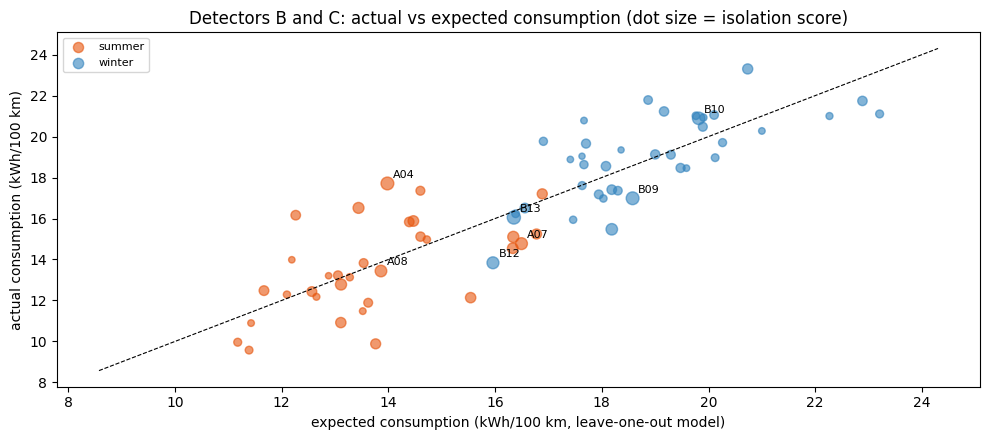

In [8]:
fig, ax = plt.subplots(figsize=(10, 4.5))
for s, c in SEASON_COLORS.items():
    d = trip[trip.season == s]
    ax.scatter(d.expected_kwh_per_100km, d.consumption_kwh_per_100km, s=20 + 300 * (d.isolation_score - trip.isolation_score.min()),
               color=c, alpha=0.6, label=s)
hit = trip[trip.flag_c | (trip.z_consumption.abs() > Z_LIMIT)]
for r in hit.itertuples():
    ax.annotate(r.trip_id.replace("Trip", ""), (r.expected_kwh_per_100km, r.consumption_kwh_per_100km), fontsize=8,
                xytext=(4, 4), textcoords="offset points")
lim = [trip[["expected_kwh_per_100km", "consumption_kwh_per_100km"]].min().min() - 1,
       trip[["expected_kwh_per_100km", "consumption_kwh_per_100km"]].max().max() + 1]
ax.plot(lim, lim, "k--", lw=0.8)
ax.set(xlabel="expected consumption (kWh/100 km, leave-one-out model)", ylabel="actual consumption (kWh/100 km)",
       title="Detectors B and C: actual vs expected consumption (dot size = isolation score)")
ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(FIGURES / "06_trip_anomalies.png", dpi=150)
plt.show()

## D · Signal-quality flags from data preparation

In [9]:
dq = con.sql("""
    SELECT trip_id,
           avg(heating_can_invalid::INT) AS stale_heating_share,
           sum(heating_extreme::INT)     AS heating_extreme_samples,
           avg(soc_gap::INT)             AS soc_gap_share
    FROM clean.trip_signals GROUP BY 1
""").df()
for r in dq.itertuples():
    if r.stale_heating_share > 0.05:
        flags.append(dict(level="trip", trip_id=r.trip_id, time_s=np.nan, detector="D · signal quality",
                          score=round(r.stale_heating_share, 3),
                          reason=f"CAN heating power stale in {r.stale_heating_share:.0%} of samples (heating reported, none requested)"))
    if r.heating_extreme_samples > 0:
        flags.append(dict(level="trip", trip_id=r.trip_id, time_s=np.nan, detector="D · signal quality",
                          score=float(r.heating_extreme_samples),
                          reason=f"extreme heating power above 14 kW for {r.heating_extreme_samples / 10:.0f} s, "
                                 "confirmed by four independent signals: a real event, check the heater control"))
    if r.soc_gap_share > 0:
        flags.append(dict(level="trip", trip_id=r.trip_id, time_s=np.nan, detector="D · signal quality",
                          score=round(r.soc_gap_share, 3),
                          reason=f"SoC not logged for the last {r.soc_gap_share:.0%} of the trip"))
print(f"signal-quality flags: {sum(f['detector'].startswith('D') for f in flags)}")

signal-quality flags: 15


## Flag register

In [10]:
register = pd.DataFrame(flags).merge(con.sql("SELECT trip_id, season, route FROM clean.trips").df(), on="trip_id")
register = register.sort_values(["detector", "score"], ascending=[True, False], key=lambda s: s.abs() if s.dtype != object else s)
register.insert(0, "flag_id", range(1, len(register) + 1))
print(register.groupby("detector").agg(flags=("flag_id", "size"), trips=("trip_id", "nunique")).to_string())
multi = register.groupby("trip_id").detector.nunique()
print("\ntrips flagged by more than one detector:", multi[multi > 1].to_dict())
register[["flag_id", "detector", "level", "trip_id", "season", "time_s", "score", "reason"]]

                          flags  trips
detector                              
A · battery resistance       18      7
C · unusual trip profile      7      7
D · signal quality           15     15

trips flagged by more than one detector: {'TripA04': 2, 'TripA08': 2, 'TripB02': 2, 'TripB09': 3, 'TripB10': 2}


,flag_id,detector,level,trip_id,season,time_s,score,reason
17,1,A · battery resistance,event,TripB25,winter,353.5,7.480,"resistance 224 mΩ vs about 121 mΩ expected at 12 °C (1.8×); SoC 39 %: the expected curve ignores SoC, and resistance..."
2,2,A · battery resistance,event,TripB02,winter,1346.0,7.180,"resistance 187 mΩ vs about 104 mΩ expected at 16 °C (1.8×); moderate current (112 A), so the estimate is noisier"
15,3,A · battery resistance,event,TripB25,winter,319.5,6.850,"resistance 204 mΩ vs about 116 mΩ expected at 13 °C (1.8×); SoC 41 %: the expected curve ignores SoC, and resistance..."
11,4,A · battery resistance,event,TripB14,winter,2547.3,6.750,"resistance 211 mΩ vs about 121 mΩ expected at 12 °C (1.7×); SoC 48 %: the expected curve ignores SoC, and resistance..."
10,5,A · battery resistance,event,TripB14,winter,2538.8,6.560,"resistance 208 mΩ vs about 121 mΩ expected at 12 °C (1.7×); SoC 48 %: the expected curve ignores SoC, and resistance..."
9,6,A · battery resistance,event,TripB14,winter,2523.7,6.430,"resistance 197 mΩ vs about 116 mΩ expected at 13 °C (1.7×); SoC 49 %: the expected curve ignores SoC, and resistance..."
16,7,A · battery resistance,event,TripB25,winter,341.4,6.360,"resistance 196 mΩ vs about 116 mΩ expected at 13 °C (1.7×); SoC 40 %: the expected curve ignores SoC, and resistance..."
14,8,A · battery resistance,event,TripB25,winter,312.7,5.900,"resistance 197 mΩ vs about 121 mΩ expected at 12 °C (1.6×); SoC 41 %: the expected curve ignores SoC, and resistance..."
12,9,A · battery resistance,event,TripB14,winter,2556.3,5.470,"resistance 190 mΩ vs about 121 mΩ expected at 12 °C (1.6×); SoC 47 %: the expected curve ignores SoC, and resistance..."
13,10,A · battery resistance,event,TripB19,winter,623.1,5.090,"resistance 221 mΩ vs about 146 mΩ expected at 8 °C (1.5×); moderate current (102 A), so the estimate is noisier"


In [11]:
con.execute("DROP SCHEMA IF EXISTS anomaly CASCADE")
con.execute("CREATE SCHEMA anomaly")
resistance_events = ev[["trip_id", "season", "start_s", "batt_temp_c", "soc_pct", "current_at_max_sag_a", "max_sag_v",
                        "apparent_resistance_mohm", "expected_resistance_mohm", "resistance_ratio", "z", "flag"]]
trip_scores = trip[["trip_id", "season", "consumption_kwh_per_100km", "expected_kwh_per_100km", "consumption_residual",
                    "z_consumption", "isolation_score", "flag_c"]]
for table, frame in {"anomaly.flags": register, "anomaly.resistance_events": resistance_events,
                     "anomaly.trip_scores": trip_scores}.items():
    con.register("frame_view", frame)
    con.execute(f"CREATE TABLE {table} AS SELECT * FROM frame_view")
    con.unregister("frame_view")
register.to_csv(REPORTS / "06_anomaly_flags.csv", index=False)
con.close()
print(f"saved {len(register)} flags")

saved 40 flags


## 5 · Findings

**40 flags in total, across 23 trips.** Five trips are flagged by more than one detector: B09 (3), A04, A08, B02 and B10.

**A · Battery resistance:** 18 of 556 sag events (3 %) show a resistance well above what their temperature predicts (up to 1.8×).
- They cluster in TripB14 (6 events) and TripB25 (4 events). Clustering points to a persistent battery state during
  those minutes, not single noisy readings.
- The clustered events (B14, B25) and the B09 events, 11 of the 18, sit at **SoC below 50 %**, and most flags occur at
  moderate current (about 100 A), where the estimate is noisier. The expected curve models temperature only, so the
  most likely explanation for the clusters is the extra resistance at lower SoC. Adding SoC to the expected curve
  is the next refinement.

**B · Unexpected consumption: no trip flagged.**
- The leave-one-out model explains every trip's consumption within the limit (largest |z| is 2.5, mean error 1.3 kWh/100 km).
- Once temperature, speed, time stopped and climate load are known, no trip used unexplained energy. That is a useful
  negative result: there is no hidden consumption problem in this vehicle's data.

**C · Unusual trip profile:** 7 trips (10 %) are unusual for their season, each with a readable reason:
- **TripB13:** regeneration share high for winter, with a warmer battery than usual.
- **TripA04:** very fast battery warm-up on a short, fast trip (about 103 km/h on average).
- **TripB09 and TripB10:** many voltage-sag events. B09 includes charging, and B10 is a highway trip in the cold.
- **TripA08:** a lot of time stopped.

**D · Signal quality:** 15 recordings carry known logging problems:
- **10 summer trips:** stale CAN heating values.
- **4 winter trips:** SoC not logged towards the end.
- **TripB02:** the real 23–26 kW heating event, which should be checked against heater control.

**Root-cause notes** are generated for every flag (`anomaly.flags.reason`). They state the measured value against
the expected value and the conditions that most likely explain it.